In [2]:
import os
os.environ["OMP_NUM_THREADS"] = "1" # for this perticular kernel session seting the threads to 4 for preventing memory leak.

In [3]:
import seaborn as sns
from sklearn.datasets import make_blobs # this provides data for clusturing also this gives o/p labels which we will avoid here 

In [4]:
X,y= make_blobs(
    n_samples=1000, 
    n_features=2, # for 2 dimentions only
    centers=4, # this means we want to have 4 true clustures , here its just for example ,we will find it first
    random_state=42
)

<Axes: >

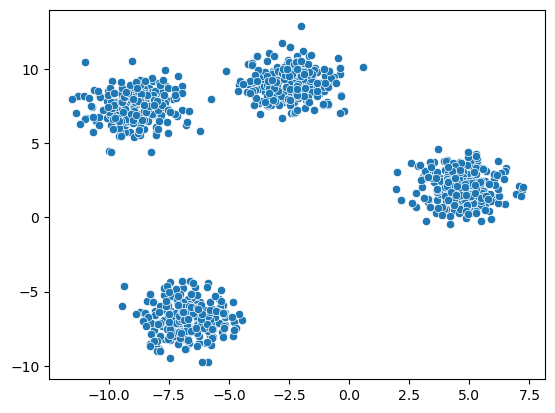

In [5]:
# visualisation 
sns.scatterplot(x=X[:,0], y=X[:,1]) # this will give ous a view of samples of both the features through both axis

In [6]:
# K-means clustering 
from sklearn.cluster import KMeans

In [7]:
K=4

kmeans=KMeans(  # we also have to choose the initiation algo which by default is KMeans ++
    n_clusters=K, 
    random_state=42
)

In [8]:
labels= kmeans.fit_predict(X)

<Axes: >

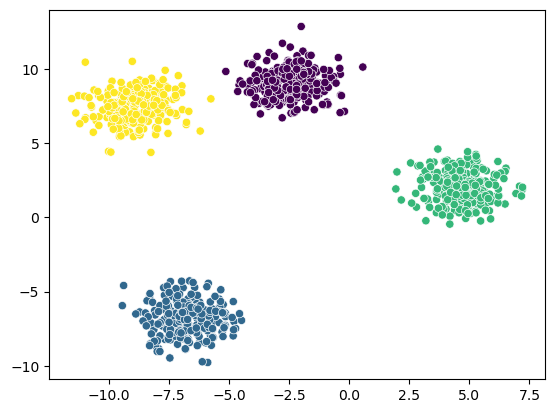

In [9]:
sns.scatterplot(x=X[:,0], y=X[:,1], c=labels)

# Choosing K-value - Elbow method

In [11]:
wcss= []
for k in range(1,21):
    kmean= KMeans(n_clusters=k) 
    kmean.fit_predict(X)
    wcss.append(kmean.inertia_) # the inertia parameter stores all the wcss values and here we are transfering it.

<Axes: >

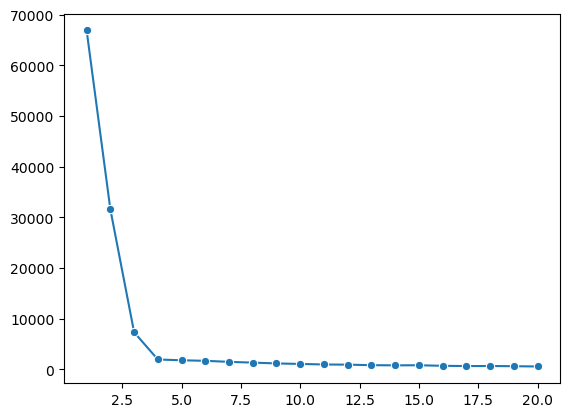

In [12]:
sns.lineplot(x=range(1,21), y=wcss, marker="o") 
# Here we can see the elbow point is somewhere around 4, as we have used earlier.

In [13]:
# to automate this task we can use kneed module 
!pip install kneed

In [14]:
from kneed import KneeLocator # it basically locates the elbow/knee point if the graph reembles to its 4 varients

In [15]:
knee= KneeLocator(range(1,21), wcss, curve="convex", direction="decreasing")
# everything about the curve needs to be specified (x_value, y_value, type of curve and direction of it)

In [16]:
print("Optimal k value:",knee.elbow) # or we can say it knee.knee

Optimal k value: 4


# Silhoutte score

In [18]:
from sklearn.metrics import silhouette_score

In [19]:
ss= []
for k in range(2,21):  # For ssilhouette_score we always start with 2 clustures since everything init is dependent on distance b/w clustures 
    kmean= KMeans(n_clusters=k) 
    label=kmean.fit_predict(X)
    score=silhouette_score(X, label)

    ss.append(score)

<Axes: >

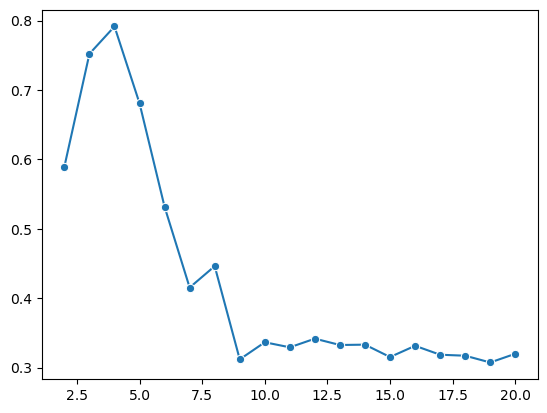

In [20]:
sns.lineplot(x=range(2,21), y=ss, marker="o") 
# we can again say its 4

# Practice-kmeans on iris data

In [22]:
from sklearn.datasets import load_iris
import pandas as pd

In [23]:
iris= load_iris()
X= iris.data
y= iris.target

<Axes: >

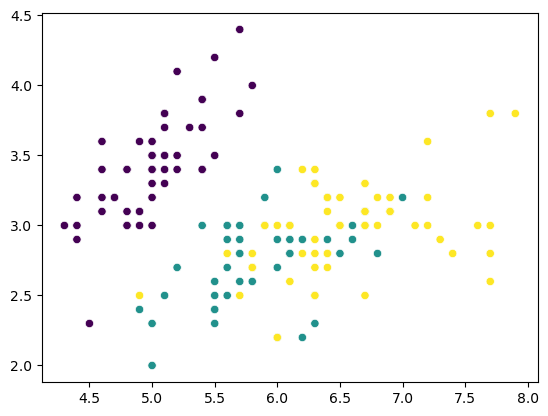

In [60]:
# Visualisation 
sns.scatterplot(x=X[:,0],y=X[:,1], c=y)

In [25]:
# scaling data to give equal importance
from sklearn.preprocessing import StandardScaler

scaler= StandardScaler()
X_scaled= scaler.fit_transform(X)

In [26]:
# Elbow method 
wcss=[]
for k in range(1,11):
    kmean= KMeans(n_clusters=k)
    kmean.fit(X_scaled)
    wcss.append(kmean.inertia_)

<Axes: >

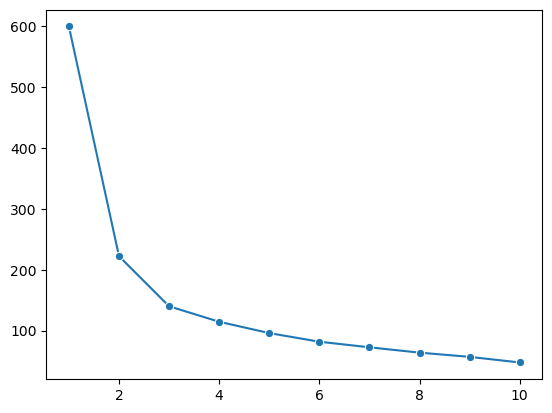

In [52]:
sns.lineplot(x=range(1,11),y=wcss,marker="o")

In [54]:
knee= KneeLocator(range(1,11), wcss, curve="convex", direction="decreasing")
print("Optimal k value:",knee.elbow)

Optimal k value: 3


<Axes: >

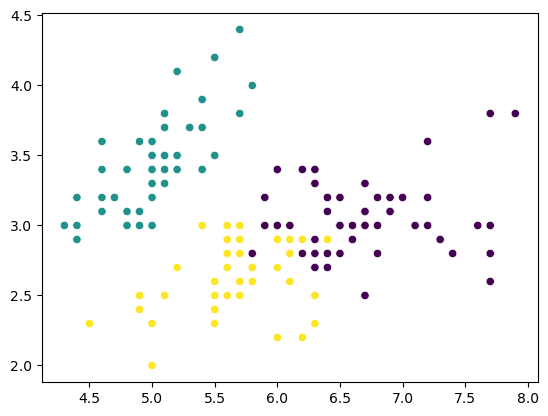

In [58]:
# kmeans

kmean= KMeans(n_clusters=3)
label=kmean.fit_predict(X_scaled)

sns.scatterplot(x=X[:,0],y=X[:,1], c=label)

In [62]:
# Dimentionality reduction using PCA
from sklearn.decomposition import PCA 
pca= PCA(n_components=2) # all the features will be merged and at last we will have only 2
pca_data= pca.fit_transform(X_scaled)

<Axes: >

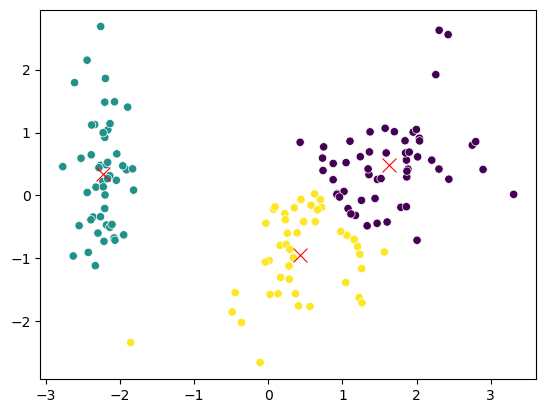

In [74]:
kmean= KMeans(n_clusters=3, random_state=10)
label=kmean.fit_predict(pca_data)

sns.scatterplot(x=pca_data[:,0],y=pca_data[:,1], c=label)
sns.scatterplot(x=kmean.cluster_centers_[:,0],y=kmean.cluster_centers_[:,1], marker="x", c="red", s=100)